CS156 — Session 19: Shakespeare RNN
Extension Question — TensorFlow text-generation tutorial

1. Setup
What am I doing? I am loading TensorFlow and checking the available hardware.

TensorFlow builds the RNN and handles training.
A GPU can make training faster, but the code also works on a CPU.

In [ ]:
# Loading the libraries and setting a seed
import os
import time

import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: []


2. Download and inspect the Shakespeare dataset
What am I doing? I am loading the original text used in the tutorial.

The model receives individual characters instead of complete words.
I check the text length, its beginning, and the unique characters it contains.

In [ ]:
# Downloading Shakespeare's text
url = "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
path_to_file = tf.keras.utils.get_file("shakespeare.txt", origin=url)

# Reading the text and examining its characters
with open(path_to_file, "r", encoding="utf-8") as file:
    text = file.read()

vocab = sorted(set(text))

print("Number of characters:", len(text))
print("Unique characters:", len(vocab))
print("\nFirst 250 characters:\n")
print(text[:250])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of characters: 1115394
Unique characters: 65

First 250 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



My interpretation: The model learns from the order of characters.
It is not given a dictionary or rules for writing dialogue.

3. Process the text
3.1 Turn characters into numerical IDs
What am I doing? I am converting text into numbers that the neural network can process.

StringLookup gives each character its own ID.
A second lookup converts IDs back into readable characters.
The extra [UNK] ID represents unknown characters.

In [ ]:
# Creating the character-to-ID mapping
ids_from_chars = tf.keras.layers.StringLookup(vocabulary=vocab, mask_token=None)
chars_from_ids = tf.keras.layers.StringLookup(
    vocabulary=ids_from_chars.get_vocabulary(), invert=True, mask_token=None
)

# Joining the recovered characters into readable text
def text_from_ids(ids):
    return tf.strings.reduce_join(chars_from_ids(ids), axis=-1)

# Checking the conversion in both directions
example_chars = tf.strings.unicode_split(["Hello"], "UTF-8")
example_ids = ids_from_chars(example_chars)
recovered = text_from_ids(example_ids)

print("Character IDs:", example_ids.to_list())
print("Recovered text:", recovered.numpy()[0].decode("utf-8"))
print("Vocabulary size including [UNK]:", len(ids_from_chars.get_vocabulary()))

assert recovered.numpy()[0].decode("utf-8") == "Hello"

Character IDs: [[21, 44, 51, 51, 54]]
Recovered text: Hello
Vocabulary size including [UNK]: 66


3.2 Create training inputs and targets
What question am I answering? How can the network learn to predict the next character?

I divide the text into sequences of 101 characters.
The first 100 characters are inputs.
The final 100 characters become targets, shifted one position forward.

For example, an input of Hell has the target ello.
This teaches the model which character should come next at every position.

In [ ]:
# Turning the full text into a sequence of IDs
all_ids = ids_from_chars(tf.strings.unicode_split(text, "UTF-8"))
ids_dataset = tf.data.Dataset.from_tensor_slices(all_ids)

# Grouping 101 characters to make 100 input-target pairs
SEQ_LENGTH = 100
sequences = ids_dataset.batch(SEQ_LENGTH + 1, drop_remainder=True)

def split_input_target(sequence):
    return sequence[:-1], sequence[1:]

training_pairs = sequences.map(split_input_target, num_parallel_calls=tf.data.AUTOTUNE)

# Showing one input and its matching target
for input_text, target_text in training_pairs.take(1):
    print("Input:\n", text_from_ids(input_text).numpy().decode("utf-8"))
    print("\nTarget:\n", text_from_ids(target_text).numpy().decode("utf-8"))
    assert input_text.shape == (SEQ_LENGTH,)
    assert target_text.shape == (SEQ_LENGTH,)

Input:
 First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You

Target:
 irst Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You 


3.3 Create training batches
What am I doing? I am grouping several sequences into each training batch.

The RNN processes 64 sequences together.
The samples remain independent, but character order stays intact within each sequence.
Shuffling helps the model learn from examples in a different order.

In [ ]:
# Preparing batches for training
BATCH_SIZE = 64
BUFFER_SIZE = 10000

dataset = (
    training_pairs
    .shuffle(BUFFER_SIZE, seed=42)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

for input_batch, target_batch in dataset.take(1):
    print("Inputs:", input_batch.shape)
    print("Targets:", target_batch.shape)
    assert input_batch.shape == (BATCH_SIZE, SEQ_LENGTH)

Inputs: (64, 100)
Targets: (64, 100)


4. Build the model
What question am I answering? How does the network predict the next character?

I use the tutorial's three main layers:
- Embedding: Turns each character ID into a learned vector.
- GRU: Reads the vectors in order and carries a hidden state forward.
- Dense: Produces one prediction score for each possible next character.
A GRU is a gated recurrent unit.
Its gates help retain useful earlier information.

I create two model views using the same layers and weights.
One supports training and normal predictions.
The other allows me to supply a previous hidden state during text generation.
This keeps the GRU's input state explicit and avoids the sample's training error.

In [ ]:
# Setting the tutorial's model sizes
VOCAB_SIZE = len(ids_from_chars.get_vocabulary())
EMBEDDING_DIM = 256
RNN_UNITS = 1024

# Creating the shared neural network layers
embedding_layer = tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, name="embedding")
gru_layer = tf.keras.layers.GRU(
    RNN_UNITS, return_sequences=True, return_state=True, name="gru"
)
dense_layer = tf.keras.layers.Dense(VOCAB_SIZE, name="character_scores")

# Building the model used for training
input_ids = tf.keras.Input(shape=(None,), dtype=tf.int64, name="input_ids")
x = embedding_layer(input_ids)
gru_outputs, final_state = gru_layer(x)
logits = dense_layer(gru_outputs)

model = tf.keras.Model(inputs=input_ids, outputs=logits, name="shakespeare_rnn")
seed_model = tf.keras.Model(inputs=input_ids, outputs=[logits, final_state], name="seed_model")

# Building a second view that accepts a previous hidden state
generation_ids = tf.keras.Input(shape=(None,), dtype=tf.int64, name="generation_ids")
previous_state = tf.keras.Input(shape=(RNN_UNITS,), dtype=tf.float32, name="previous_state")
generation_embeddings = embedding_layer(generation_ids)
generation_outputs, new_state = gru_layer(
    generation_embeddings, initial_state=[previous_state]
)
generation_logits = dense_layer(generation_outputs)

generation_model = tf.keras.Model(
    inputs=[generation_ids, previous_state],
    outputs=[generation_logits, new_state],
    name="generation_model"
)

print("Training model and generation model share the same layers.")
model.summary()

Training model and generation model share the same layers.


Model: "shakespeare_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)          │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ [(None, None, 1024),   │     3,938,304 │
│                                 │ (None, 1024)]          │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ character_scores (Dense)        │ (None, None, 66)       │        67,650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,022,850 (15.35 MB)

 Trainable params: 4,022,850 (15.35 MB)

 Non-trainable params: 0 (0.00 B)

5. Try the model before training
What am I checking? I am verifying the predicted output dimensions.

The model returns a score for every character at every time step.
The expected shape is (64, 100, vocabulary size).
Its predictions should initially look random because it has not learned anything.

In [ ]:
# Testing prediction dimensions before training
for input_batch, target_batch in dataset.take(1):
    untrained_logits = model(input_batch, training=False)
    print("Input shape:", input_batch.shape)
    print("Prediction shape:", untrained_logits.shape)

assert untrained_logits.shape == (BATCH_SIZE, SEQ_LENGTH, VOCAB_SIZE)

# Checking the hidden-state connection before training
seed_test_ids = tf.constant([[1, 2, 3]], dtype=tf.int64)
seed_test_logits, seed_test_state = seed_model(seed_test_ids, training=False)
step_test_logits, step_test_state = generation_model(
    [tf.constant([[4]], dtype=tf.int64), seed_test_state], training=False
)

assert seed_test_state.shape == (1, RNN_UNITS)
assert step_test_logits.shape == (1, 1, VOCAB_SIZE)
assert step_test_state.shape == (1, RNN_UNITS)
print("State transfer test: passed")

# Sampling a next character for each position in one sequence
sampled_ids = tf.random.categorical(untrained_logits[0], num_samples=1)
sampled_ids = tf.squeeze(sampled_ids, axis=-1)

print("\nInput sample:\n", text_from_ids(input_batch[0]).numpy().decode("utf-8"))
print("\nUntrained predictions:\n", text_from_ids(sampled_ids).numpy().decode("utf-8"))

Input shape: (64, 100)
Prediction shape: (64, 100, 66)
State transfer test: passed

Input sample:
 y, point by point,
Thereby to see the minutes how they run,
How many make the hour full complete;
Ho

Untrained predictions:
 GoDunR$Z&&pqEoYy$Cq[UNK]!cQYB;HzKp3M'osTki;KHJRJtWbC!ooo'zkiZNIof
R
jYX3HHDw
OYH&HWrwMOVsaEGPZTrTD

Xzz



My interpretation: The output shape shows that every character position receives a prediction.
The random text is expected before training.
Sampling makes a character choice using the predicted scores.

6. Train the model
6.1 Choose the loss function and optimizer
What am I doing? I am defining how the model measures mistakes.

I use sparse categorical cross-entropy because the correct next character is a single ID.
from_logits=True tells TensorFlow that the model returns raw scores, not probabilities.
The Adam optimizer adjusts weights to reduce this loss.

In [ ]:
# Checking the initial loss
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
initial_loss = loss_fn(target_batch, untrained_logits)

print("Initial loss:", float(initial_loss))
print("exp(initial loss):", float(tf.exp(initial_loss)))
print("Vocabulary size:", VOCAB_SIZE)

# Preparing the optimizer for training
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss=loss_fn)

# Testing one small weight update before the full training run
check_loss = model.train_on_batch(input_batch[:2, :10], target_batch[:2, :10])
print("One-batch training test passed. Loss:", float(check_loss))

Initial loss: 4.190610408782959
exp(initial loss): 66.06310272216797
Vocabulary size: 66
One-batch training test passed. Loss: 4.191066741943359


6.2 Save checkpoints and train
What am I doing? I am training the model and saving its learned weights.

During each epoch, the model predicts characters and measures the loss.
Backpropagation then adjusts the shared weights.

I use 10 epochs for a manageable Colab run.
The official tutorial also shows longer training for better text quality.
You can increase EPOCHS if needed.

The .weights.h5 ending follows current Keras checkpoint requirements

In [ ]:
# Saving model weights after each epoch
checkpoint_dir = "./training_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, "epoch_{epoch:02d}.weights.h5")
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path, save_weights_only=True, verbose=0
)

# Training the character predictor
EPOCHS = 10
history = model.fit(dataset, epochs=EPOCHS, callbacks=[checkpoint_callback], verbose=1)

Epoch 1/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1032s 6s/step - loss: 2.5583
Epoch 2/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1030s 6s/step - loss: 1.8423
Epoch 3/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1040s 6s/step - loss: 1.5985
Epoch 4/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1021s 6s/step - loss: 1.4707
Epoch 5/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1036s 6s/step - loss: 1.3914
Epoch 6/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1046s 6s/step - loss: 1.3344
Epoch 7/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1039s 6s/step - loss: 1.2875
Epoch 8/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1050s 6s/step - loss: 1.2465
Epoch 9/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1036s 6s/step - loss: 1.2076
Epoch 10/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 1064s 6s/step - loss: 1.1682


6.3 Review the training results
What am I checking? I am comparing the loss at the start and end of training.

A lower loss shows improved next-character predictions on the training data.
It does not prove the generated sentences will be meaningful.
I will check the text directly in the final section.

Epoch 01: loss = 2.5583
Epoch 02: loss = 1.8423
Epoch 03: loss = 1.5985
Epoch 04: loss = 1.4707
Epoch 05: loss = 1.3914
Epoch 06: loss = 1.3344
Epoch 07: loss = 1.2875
Epoch 08: loss = 1.2465
Epoch 09: loss = 1.2076
Epoch 10: loss = 1.1682

First epoch: 2.5583
Final epoch: 1.1682


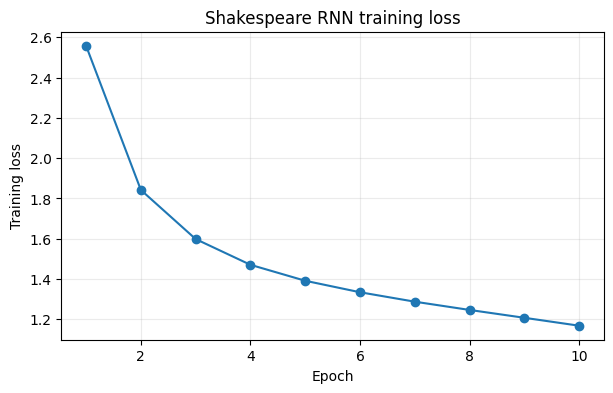

In [ ]:
# Displaying the recorded training loss
loss_values = history.history["loss"]

for epoch, value in enumerate(loss_values, start=1):
    print(f"Epoch {epoch:02d}: loss = {value:.4f}")

print(f"\nFirst epoch: {loss_values[0]:.4f}")
print(f"Final epoch: {loss_values[-1]:.4f}")

# Plotting how the loss changed across epochs
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Shakespeare RNN training loss")
plt.grid(alpha=0.25)
plt.show()

7. Generate text
What question am I answering? How can a trained RNN continue a phrase?

I start with ROMEO:.
The model reads this seed and produces a hidden state.
It predicts scores for the next character.
I sample a character using those scores and then feed it back into the model.
The updated hidden state carries context into the next step.

Temperature controls how varied the sampling is.
A lower temperature favors common characters.
A higher temperature makes unusual choices more likely.

In [ ]:
# Preventing the model from selecting the unknown-character ID
assert ids_from_chars.get_vocabulary()[0] == "[UNK]"
prediction_mask = tf.concat(
    [tf.constant([-1e9], dtype=tf.float32), tf.zeros(VOCAB_SIZE - 1)], axis=0
)

# Compiling one small generation step for faster repeated predictions
TEMPERATURE = 1.0

@tf.function(input_signature=[
    tf.TensorSpec(shape=(1, 1), dtype=tf.int64),
    tf.TensorSpec(shape=(1, RNN_UNITS), dtype=tf.float32)
])
def generate_one_step(current_id, current_state):
    # Predicting from the current character and previous state
    scores, next_state = generation_model([current_id, current_state], training=False)
    next_logits = scores[:, -1, :] / TEMPERATURE

    # Sampling one character while excluding the unknown token
    next_logits = next_logits + prediction_mask[None, :]
    next_id = tf.random.categorical(next_logits, num_samples=1, dtype=tf.int64)
    return next_id, next_state

print("The generator is ready.")

The generator is ready.


7.1 Generate 1,000 new characters
What am I doing? I am producing new text from the trained model.

The seed is processed once to obtain the first prediction and hidden state.
After that, the same generation step repeats for each new character.

The model generates text one character at a time.
Each new character and hidden state help decide the next prediction.

In [ ]:
# Processing the starting phrase
start_time = time.time()
seed = tf.constant(["ROMEO:"])
seed_ids = ids_from_chars(tf.strings.unicode_split(seed, "UTF-8")).to_tensor()
seed_scores, state = seed_model(seed_ids, training=False)

# Sampling the first new character after the seed
first_logits = seed_scores[:, -1, :] / TEMPERATURE
first_logits = first_logits + prediction_mask[None, :]
next_id = tf.random.categorical(first_logits, num_samples=1, dtype=tf.int64)

# Generating the remaining characters using the updated hidden state
NEW_CHARACTERS = 1000
generated = [seed.numpy()[0].decode("utf-8")]
generated.append(chars_from_ids(next_id[0, 0]).numpy().decode("utf-8"))

for _ in range(NEW_CHARACTERS - 1):
    next_id, state = generate_one_step(next_id, state)
    generated.append(chars_from_ids(next_id[0, 0]).numpy().decode("utf-8"))

# Showing the generated text
result = "".join(generated)
print(result)
print("\nGenerated characters:", len(result) - len(generated[0]))
print("Elapsed seconds:", round(time.time() - start_time, 2))

assert len(result) - len(generated[0]) == NEW_CHARACTERS

ROMEO:
To do them follow.

TYBALT:
They small, for by the state set poor music?

LADY ANNE:
If
here we nor prepare for me to the king:
Come, sir; for thy last-plagious friends! Alas!
That wide, that who may your think asis, that you
may burst beggars, what is no wrattle roam,
For mortal friends to oug yourself! lords, if I
Romeo are pleased, yet thinks he shall not govern for him:
Though I cannot apot Suncition was the drops
How it is a nealth; and now, Erenou had slip
vile wing, that hald by this nature?

JULIET:
Yes, be young condemnny, conduct rise a gumple
That upon this puside, as not arm,
Die that the fill:--a sudden! speak this at hims!
And yours my bony have.

HERMIONE:
What, traitor, I'll watch my hand fault that Placious tribune!

TRANIO:
Narce, I saw himself, sweet sweet aside! the treat man
Which over-own payling of a lumb in
treeply; for this one is well as I perceive
She, farewell. A crown shows himself,--

DUKE VINCENTIO:
Nor any man most obey villains!

Nurse:
Well, I s

7.2 My interpretation of the generated text
I expect the model to copy some writing patterns from Shakespeare's plays.
These patterns may include capitalized speaker names, punctuation, and dialogue formatting.

The model learns to predict characters rather than understand the meaning of the story.
Some lines may look like Shakespeare without making complete sense.

I should review the actual generated text before claiming which patterns appeared.
Training loss alone cannot confirm that the output is meaningful.

8. Short answers for Question 6

What is tf.keras.layers.Embedding?
It turns each character ID into a learned vector of numbers.
The model adjusts these vectors during training to capture useful patterns.

What is a GRU, and why use it instead of a vanilla RNN?
A GRU is a Gated Recurrent Unit.
Its gates control how much earlier information is kept or updated.
This helps it learn relationships across longer sequences.
It can reduce vanishing-gradient problems compared with a basic RNN.
It does not completely remove gradient problems.

How does text generation work?
I give the trained model a starting phrase.
The model converts its characters to IDs and updates its hidden state.
It predicts scores for the next character.
I adjust those scores using temperature and sample one character.
I feed the new character and hidden state into the model again.
Repeating this process builds new text one character at a time.